<a href="https://colab.research.google.com/github/YousraAndoulla/rag-retrieval-error-analysis1/blob/main/Proving_the_Root_Cause.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/drive/MyDrive/synthetic_log_file1.csv')

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())

   user_id user_intent            timestamp retrieval_status  \
0       50   complaint  2023-10-01 00:27:00          success   
1       22   complaint  2023-10-01 00:38:00             miss   
2      161   complaint  2023-10-01 00:51:00             miss   
3      151     support  2023-10-01 00:54:00             miss   
4       17     inquiry  2023-10-01 01:12:00          success   

       error_category  
0            no_error  
1  factual_inaccuracy  
2  factual_inaccuracy  
3            no_error  
4            no_error  
Dataset shape: (5000, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   user_id           5000 non-null   int64 
 1   user_intent       5000 non-null   object
 2   timestamp         5000 non-null   object
 3   retrieval_status  5000 non-null   object
 4   error_category    5000 non-null   object
dtypes: int64(1), 

# Analyze user intent segments

In [2]:
# Convert timestamp to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Group data by user intent
user_segments = df.groupby('user_intent')

# Count unique users in each segment
segment_counts = user_segments['user_id'].nunique()

print("Unique users by intent:")
print(segment_counts)

Unique users by intent:
user_intent
complaint          293
feature_request    290
feedback           283
inquiry            290
support            291
Name: user_id, dtype: int64


# Calculate the seven-day activity measure

In [3]:
def calculate_retention(group):
    # Count unique users active within the final 7-day window
    end_date = group['timestamp'].max()
    start_date = end_date - pd.Timedelta(days=7)

    active_users = group[
        group['timestamp'] >= start_date
    ]['user_id'].nunique()

    return active_users


retention_metrics = user_segments.apply(calculate_retention)

print("Seven-day activity measure:")
print(retention_metrics)

Seven-day activity measure:
user_intent
complaint          132
feature_request    127
feedback           122
inquiry            129
support            119
dtype: int64


/tmp/ipykernel_1758/3430141571.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  retention_metrics = user_segments.apply(calculate_retention)


# Calculate the drop-off measure

In [4]:
drop_off_rate = (
    (segment_counts - retention_metrics) / segment_counts
)

print("Drop-off measure:")
print(drop_off_rate)

highest_drop_off_intent = drop_off_rate.idxmax()

print("Intent with the highest drop-off measure:",
      highest_drop_off_intent)

Drop-off measure:
user_intent
complaint          0.549488
feature_request    0.562069
feedback           0.568905
inquiry            0.555172
support            0.591065
dtype: float64
Intent with the highest drop-off measure: support


# Filter the target intent

In [5]:
target_intent = highest_drop_off_intent

filtered = df[
    df['user_intent'] == target_intent
].copy()

print("Target intent:", target_intent)
print("Total interactions:", len(filtered))
print(filtered.head())

Target intent: support
Total interactions: 989
    user_id user_intent           timestamp retrieval_status  \
3       151     support 2023-10-01 00:54:00             miss   
7       160     support 2023-10-01 01:35:00          success   
10      141     support 2023-10-01 01:42:00             miss   
23       13     support 2023-10-01 05:27:00             miss   
28      177     support 2023-10-01 07:52:00          success   

        error_category  
3             no_error  
7             no_error  
10            no_error  
23  factual_inaccuracy  
28            no_error  


# Build the contingency table

In [6]:
contingency_table = pd.crosstab(
    filtered['retrieval_status'],
    filtered['error_category']
)

print(contingency_table)

error_category    factual_inaccuracy  no_error
retrieval_status                              
miss                              77        69
success                           50       793


# Calculate percentages

In [7]:
error_rate_table = pd.crosstab(
    filtered['retrieval_status'],
    filtered['error_category'],
    normalize='index'
)

print((error_rate_table * 100).round(1))

error_category    factual_inaccuracy  no_error
retrieval_status                              
miss                            52.7      47.3
success                          5.9      94.1


# Calculate a Correlation Metric

In [8]:
# Create a binary outcome: factual inaccuracy vs. other outcomes
filtered = filtered.copy()

filtered['factual_error'] = (
    filtered['error_category'] == 'factual_inaccuracy'
)

filtered['retrieval_miss'] = (
    filtered['retrieval_status'] == 'miss'
)

# Build a 2x2 table
phi_table = pd.crosstab(
    filtered['retrieval_miss'],
    filtered['factual_error']
).reindex(
    index=[True, False],
    columns=[True, False],
    fill_value=0
)

print(phi_table)

# Extract the four counts
a = phi_table.loc[True, True]    # Miss + factual error
b = phi_table.loc[True, False]   # Miss + no factual error
c = phi_table.loc[False, True]   # Success + factual error
d = phi_table.loc[False, False]  # Success + no factual error

denominator = np.sqrt(
    (a + b) * (c + d) * (a + c) * (b + d)
)

phi = (a * d - b * c) / denominator if denominator else np.nan

print("Phi coefficient:", round(phi, 3))

factual_error   True   False
retrieval_miss              
True               77     69
False              50    793
Phi coefficient: 0.496


# Visualization

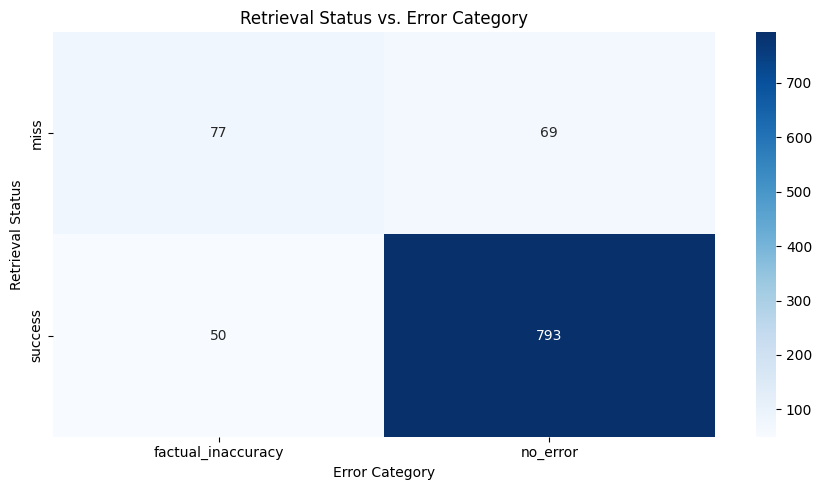

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Retrieval Status vs. Error Category')
plt.xlabel('Error Category')
plt.ylabel('Retrieval Status')
plt.tight_layout()
plt.show()